In [1]:
import sys
from pathlib import Path

repo_root = Path.cwd().resolve().parent
sys.path.insert(0, str(repo_root))

from ecephys_setup import get_session, get_units, get_spikes, clean_grating_spike_data

import numpy as np
import pandas as pd

import torch  
import torch.nn as nn  
import torch.optim as optim
import torch.nn.functional as F 
from torch.utils.data import TensorDataset, DataLoader

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

from allensdk.brain_observatory.ecephys.ecephys_project_cache import EcephysProjectCache

c:\Users\taeju\miniforge3\envs\allensdk-test\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
session = get_session(715093703)
presentations, units = get_units(session, region="VISp")

# Keep grating trials with a numeric orientation.
orientations = pd.to_numeric(presentations["orientation"], errors="coerce")
orientation_labels = orientations.dropna()
trials = presentations.loc[orientation_labels.index]

spikes = get_spikes(session, trials, units)
counts = spikes.groupby(["stimulus_presentation_id", "unit_id"]).size()

visp_spikes_int = (
    counts.unstack("unit_id", fill_value=0)
    .reindex(index=trials.index, columns=units.index, fill_value=0)
    .astype(int)
)

print(f"{visp_spikes_int.shape[0]} trials × {visp_spikes_int.shape[1]} units")

c:\Users\taeju\miniforge3\envs\allensdk-test\lib\site-packages\hdmf\spec\namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.2.2, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)


598 trials × 60 units


In [3]:
# Use GPU if available  
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [4]:
# VAE encoder
class Encoder(nn.Module):  
    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=20):  
        super(Encoder, self).__init__()  
        self.fc1 = nn.Linear(input_dim, hidden_dim)  
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)  
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim) 

    def forward(self, X): 
        h = torch.relu(self.fc1(X)) 
        mu = self.fc_mu(h) 
        logvar = self.fc_logvar(h) 
        return mu, logvar

# VAE decoder
class Decoder(nn.Module):  
    def __init__(self, latent_dim=20, hidden_dim=400, output_dim=784, likelihood="gaussian"):  
        super(Decoder, self).__init__()
        self.likelihood = likelihood
        self.fc1 = nn.Linear(latent_dim, hidden_dim)  
        self.fc2 = nn.Linear(hidden_dim, output_dim)
    
    def forward(self, z):
        h = torch.relu(self.fc1(z))
        out = self.fc2(h)
        if self.likelihood == "poisson":
            return F.softplus(out)      # rate λ > 0
        else:
            return out                  # Gaussian mean (real-valued)

In [5]:
# VAE class, combining encoder and decoder
class VAE(nn.Module):  
    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=20, likelihood="gaussian"):  
        super(VAE, self).__init__()  
        self.encoder = Encoder(input_dim, hidden_dim, latent_dim)  
        self.decoder = Decoder(latent_dim, hidden_dim, input_dim, likelihood=likelihood)  
    
    def reparameterize(self, mu, logvar):  
        std = torch.exp(0.5 * logvar)  # Standard deviation  
        eps = torch.randn_like(std)    # Random noise  
        return mu + eps * std          # Sample from the latent distribution  
        
    def forward(self, X):  
        mu, logvar = self.encoder(X)  
        z = self.reparameterize(mu, logvar)  
        reconstructed = self.decoder(z)
        return reconstructed, mu, logvar

# VAE loss, where total loss = reconstruction loss + KL divergence
def vae_loss(recon, X, mu, logvar, likelihood):
    # Reconstruction: negative log-likelihood, averaged over batch
    if likelihood == "gaussian":
        # Gaussian NLL ∝ MSE
        recon_loss = F.mse_loss(recon, X, reduction="mean")
    elif likelihood == "poisson":
        # Poisson NLL = mean over batch of sum over units (λ - k·log λ)
        log_factorial = torch.lgamma(X + 1)
        recon_loss = (recon - X * torch.log(recon + 1e-8) + log_factorial).sum(dim=1).mean()
        recon_loss = recon_loss / (X.mean() + 1e-8)
    # KL averaged over batch
    kl_loss = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1).mean()
    return recon_loss + kl_loss, recon_loss, kl_loss

In [6]:
def run_VAE(X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=2):
    # Initialize batches and model
    loader = DataLoader(TensorDataset(X), batch_size=batch_size, shuffle=True)
    
    input_dim = X.shape[1]
    model = VAE(input_dim=input_dim, latent_dim=latent_dim, likelihood=likelihood).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    
    # Track losses 
    train_losses = []
    recon_losses = []
    kl_losses = []
    
    # Training loop
    for epoch in range(n_epochs+1):
        model.train()
    
        total_train_loss = 0
        total_recon_loss = 0
        total_kl_loss = 0
        for (xb,) in loader:
            optimizer.zero_grad()
            recon, mu, logvar = model(xb)
            
            train_loss, recon_loss, kl_loss = vae_loss(recon, xb, mu, logvar, likelihood)
            total_train_loss += train_loss.item()
            total_recon_loss += recon_loss.item()
            total_kl_loss += kl_loss.item()
            
            train_loss.backward()
            optimizer.step()

        train_losses.append(total_train_loss)
        recon_losses.append(total_recon_loss)
        kl_losses.append(total_kl_loss)
        if epoch % 10 == 0:
            print(f"epoch {epoch}: loss={total_train_loss:.3f} recon={total_recon_loss:.3f} kl={total_kl_loss:.3f}")

    return model

epoch 0: loss=9264.620 recon=8676.382 kl=588.237
epoch 10: loss=2296.514 recon=1543.515 kl=752.999
epoch 20: loss=1800.271 recon=1374.602 kl=425.669
epoch 30: loss=1587.172 recon=1276.785 kl=310.387
epoch 40: loss=1535.234 recon=1294.004 kl=241.230
epoch 50: loss=1409.883 recon=1202.678 kl=207.205
epoch 60: loss=1327.239 recon=1149.705 kl=177.534
epoch 70: loss=1342.374 recon=1183.892 kl=158.482
epoch 80: loss=1275.956 recon=1121.479 kl=154.477
epoch 90: loss=1258.942 recon=1120.340 kl=138.602
epoch 100: loss=1269.254 recon=1135.765 kl=133.489
epoch 110: loss=1217.367 recon=1091.418 kl=125.948
epoch 120: loss=1233.641 recon=1107.236 kl=126.404
epoch 130: loss=1215.986 recon=1096.431 kl=119.555
epoch 140: loss=1190.544 recon=1075.029 kl=115.515
epoch 150: loss=1204.961 recon=1087.871 kl=117.089
epoch 160: loss=1139.631 recon=1029.047 kl=110.583
epoch 170: loss=1149.832 recon=1036.527 kl=113.305
epoch 180: loss=1111.456 recon=1000.530 kl=110.926
epoch 190: loss=1139.701 recon=1032.818 kl

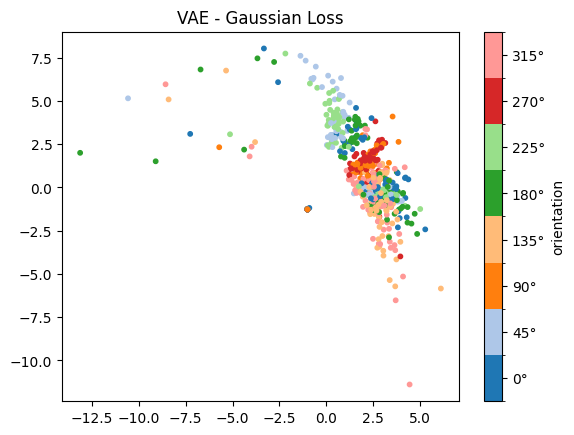

In [7]:
# Set training parameters 
n_epochs = 256
batch_size = 64
learning_rate = 1e-3 
likelihood = "gaussian"

# Initialize model, optimizer 
X = torch.tensor(visp_spikes_int.values, dtype=torch.float32).to(device)

vae_2d_model_g = run_VAE(X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=2)

vae_2d_model_g.eval()
with torch.no_grad():
    mu_all, _ = vae_2d_model_g.encoder(X) # encode all available data
    Z = mu_all.cpu().numpy()
    
cmap = plt.get_cmap("tab20")   # 10 distinct colors, take first 8
orients = np.arange(0, 360, 45)
colors = [cmap(i) for i in range(len(orients))]
norm = mcolors.BoundaryNorm(boundaries=np.arange(-45 / 2, 360, 45), ncolors=8)

sc = plt.scatter(Z[:, 0], Z[:, 1], c=orientation_labels, cmap=cmap, norm=norm, s=10)
cbar = plt.colorbar(sc, ticks=orients)
cbar.ax.set_yticklabels([f"{o}°" for o in orients])
cbar.set_label("orientation")
plt.title("VAE - Gaussian Loss")
plt.show()

epoch 0: loss=194581810076.983 recon=29454.156 kl=194581775655.646
epoch 10: loss=730.652 recon=492.249 kl=238.404
epoch 20: loss=510.953 recon=366.839 kl=144.114
epoch 30: loss=433.335 recon=311.952 kl=121.383
epoch 40: loss=372.449 recon=278.469 kl=93.979
epoch 50: loss=341.387 recon=257.755 kl=83.632
epoch 60: loss=315.525 recon=242.615 kl=72.910
epoch 70: loss=297.636 recon=231.023 kl=66.614
epoch 80: loss=284.752 recon=226.016 kl=58.735
epoch 90: loss=353.567 recon=238.616 kl=114.951
epoch 100: loss=261.798 recon=210.175 kl=51.623
epoch 110: loss=258.770 recon=213.013 kl=45.757
epoch 120: loss=246.918 recon=202.922 kl=43.996
epoch 130: loss=241.822 recon=200.014 kl=41.808
epoch 140: loss=240.371 recon=199.580 kl=40.791
epoch 150: loss=237.985 recon=200.883 kl=37.102
epoch 160: loss=231.083 recon=196.786 kl=34.297
epoch 170: loss=230.800 recon=195.079 kl=35.721
epoch 180: loss=225.323 recon=192.082 kl=33.240
epoch 190: loss=224.183 recon=192.685 kl=31.498
epoch 200: loss=221.539 re

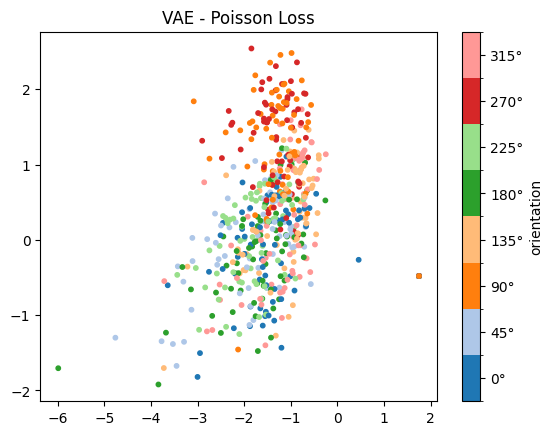

In [8]:
# Set training parameters 
n_epochs = 256
batch_size = 64
learning_rate = 1e-3 
likelihood = "poisson"

# Initialize model, optimizer 
X = torch.tensor(visp_spikes_int.values, dtype=torch.float32).to(device)

vae_2d_model_p = run_VAE(X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=2)

vae_2d_model_p.eval()
with torch.no_grad():
    mu_all, _ = vae_2d_model_p.encoder(X) # encode all available data
    Z = mu_all.cpu().numpy()
    
cmap = plt.get_cmap("tab20")   # 10 distinct colors, take first 8
orients = np.arange(0, 360, 45)
colors = [cmap(i) for i in range(len(orients))]
norm = mcolors.BoundaryNorm(boundaries=np.arange(-45 / 2, 360, 45), ncolors=8)

sc = plt.scatter(Z[:, 0], Z[:, 1], c=orientation_labels, cmap=cmap, norm=norm, s=10)
cbar = plt.colorbar(sc, ticks=orients)
cbar.ax.set_yticklabels([f"{o}°" for o in orients])
cbar.set_label("orientation")
plt.title("VAE - Poisson Loss")
plt.show()

## Let's do 3D, just for fun!

epoch 0: loss=6323228.804 recon=76426.686 kl=6246802.205
epoch 10: loss=5495.745 recon=3869.449 kl=1626.296
epoch 20: loss=2820.996 recon=1868.825 kl=952.170
epoch 30: loss=2374.204 recon=1751.857 kl=622.346
epoch 40: loss=2040.557 recon=1585.047 kl=455.510
epoch 50: loss=1953.301 recon=1561.891 kl=391.410
epoch 60: loss=1792.603 recon=1455.870 kl=336.733
epoch 70: loss=1694.339 recon=1375.225 kl=319.114
epoch 80: loss=1593.568 recon=1303.377 kl=290.191
epoch 90: loss=1549.833 recon=1279.017 kl=270.816
epoch 100: loss=1574.846 recon=1323.233 kl=251.613
epoch 110: loss=1455.076 recon=1222.895 kl=232.181
epoch 120: loss=1440.451 recon=1230.023 kl=210.429
epoch 130: loss=1484.135 recon=1278.664 kl=205.471
epoch 140: loss=1356.861 recon=1160.743 kl=196.118
epoch 150: loss=1409.243 recon=1221.395 kl=187.847
epoch 160: loss=1412.777 recon=1233.351 kl=179.426
epoch 170: loss=1371.403 recon=1199.334 kl=172.069
epoch 180: loss=1294.804 recon=1132.732 kl=162.072
epoch 190: loss=1307.022 recon=11

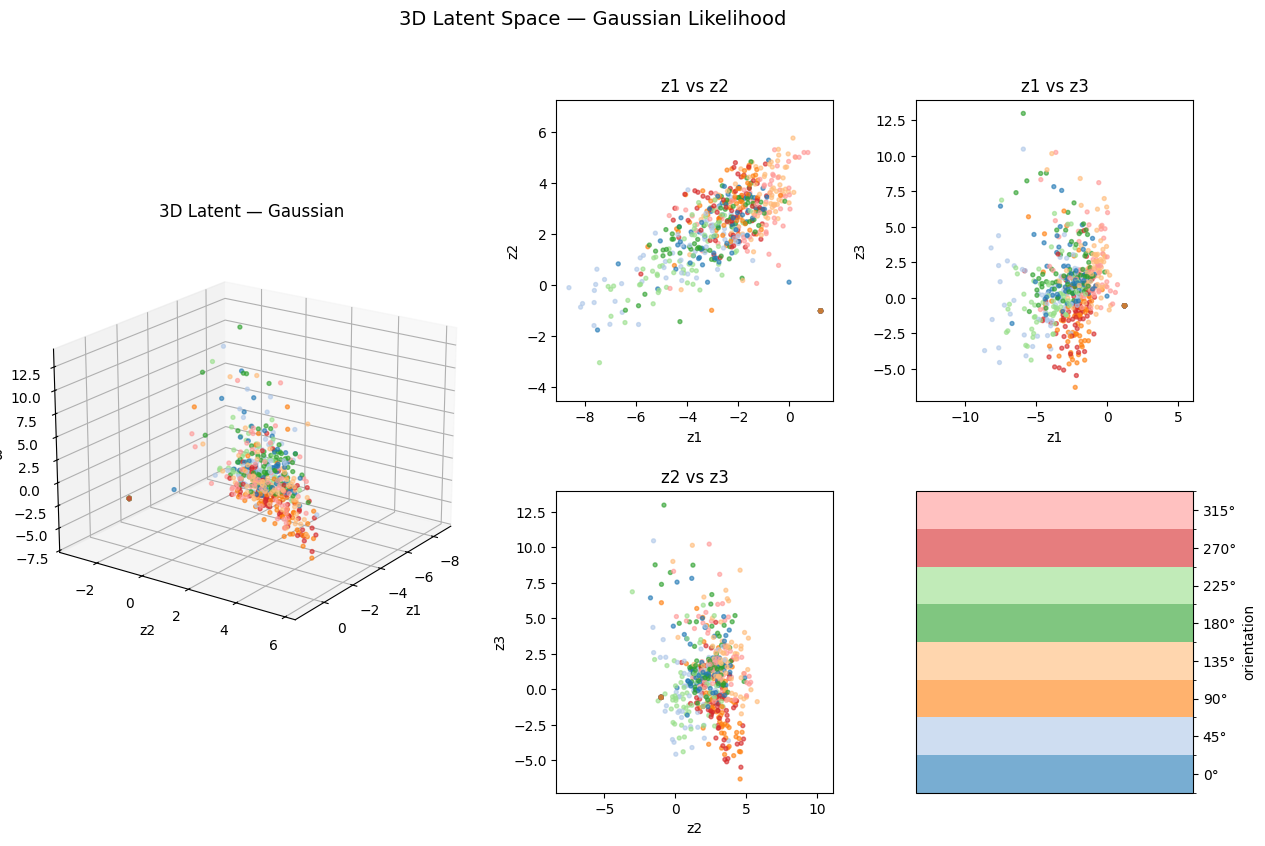

In [9]:
likelihood = "gaussian"
vae_3d_model_g = run_VAE(X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=3)

vae_3d_model_g.eval()
with torch.no_grad():
    mu_all, _ = vae_3d_model_g.encoder(X)
    Z = mu_all.cpu().numpy() # (n_trials, 3)

cmap = plt.get_cmap("tab20") # 10 distinct colors, take first 8
colors = [cmap(i) for i in range(8)]
norm = mcolors.BoundaryNorm(boundaries=np.arange(-45 / 2, 360, 45), ncolors=8)

# --- figure layout: 2 rows x 3 cols; 3D spans left column (both rows) ---
fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 3, width_ratios=[1.6, 1, 1], wspace=0.25, hspace=0.3)

# ---- (a) 3D scatter (spans left column) ----
ax3d = fig.add_subplot(gs[:, 0], projection="3d")
sc = ax3d.scatter(Z[:, 0], Z[:, 1], Z[:, 2],
                  c=orientation_labels, cmap=cmap, norm=norm,
                  s=8, alpha=0.6)
ax3d.set_xlabel("z1"); ax3d.set_ylabel("z2"); ax3d.set_zlabel("z3")
ax3d.set_title(f"3D Latent — Gaussian")
ax3d.view_init(elev=20, azim=35)

# ---- (b) three pairwise 2D projections ----
pairs = [(0, 1), (0, 2), (1, 2)]
proj_axes = [
    fig.add_subplot(gs[0, 1]),  # z1 vs z2
    fig.add_subplot(gs[0, 2]),  # z1 vs z3
    fig.add_subplot(gs[1, 1]),  # z2 vs z3
]
for ax, (i, j) in zip(proj_axes, pairs):
    ax.scatter(Z[:, i], Z[:, j], c=orientation_labels,
               cmap=cmap, norm=norm, s=8, alpha=0.6)
    ax.set_xlabel(f"z{i+1}"); ax.set_ylabel(f"z{j+1}")
    ax.set_title(f"z{i+1} vs z{j+1}")
    ax.set_aspect("equal", adjustable="datalim")

# ---- (c) shared colorbar in the bottom-right empty cell ----
cax = fig.add_subplot(gs[1, 2])
cbar = fig.colorbar(sc, cax=cax, ticks=orients)
cbar.ax.set_yticklabels([f"{o}°" for o in orients])
cbar.set_label("orientation")

plt.suptitle(f"3D Latent Space — Gaussian Likelihood", fontsize=14)
plt.show()

epoch 0: loss=2059.974 recon=1489.190 kl=570.784
epoch 10: loss=509.139 recon=357.386 kl=151.753
epoch 20: loss=361.824 recon=274.724 kl=87.100
epoch 30: loss=323.358 recon=244.998 kl=78.361
epoch 40: loss=283.969 recon=224.928 kl=59.041
epoch 50: loss=265.452 recon=209.710 kl=55.742
epoch 60: loss=252.769 recon=200.014 kl=52.754
epoch 70: loss=240.405 recon=191.304 kl=49.101
epoch 80: loss=236.721 recon=188.963 kl=47.758
epoch 90: loss=228.271 recon=182.891 kl=45.380
epoch 100: loss=221.254 recon=175.840 kl=45.414
epoch 110: loss=215.519 recon=174.375 kl=41.144
epoch 120: loss=218.680 recon=174.154 kl=44.526
epoch 130: loss=215.230 recon=174.335 kl=40.895
epoch 140: loss=209.506 recon=169.828 kl=39.678
epoch 150: loss=207.588 recon=168.643 kl=38.946
epoch 160: loss=204.207 recon=166.677 kl=37.530
epoch 170: loss=203.679 recon=164.374 kl=39.305
epoch 180: loss=208.469 recon=167.380 kl=41.088
epoch 190: loss=198.049 recon=161.490 kl=36.559
epoch 200: loss=199.140 recon=163.605 kl=35.536

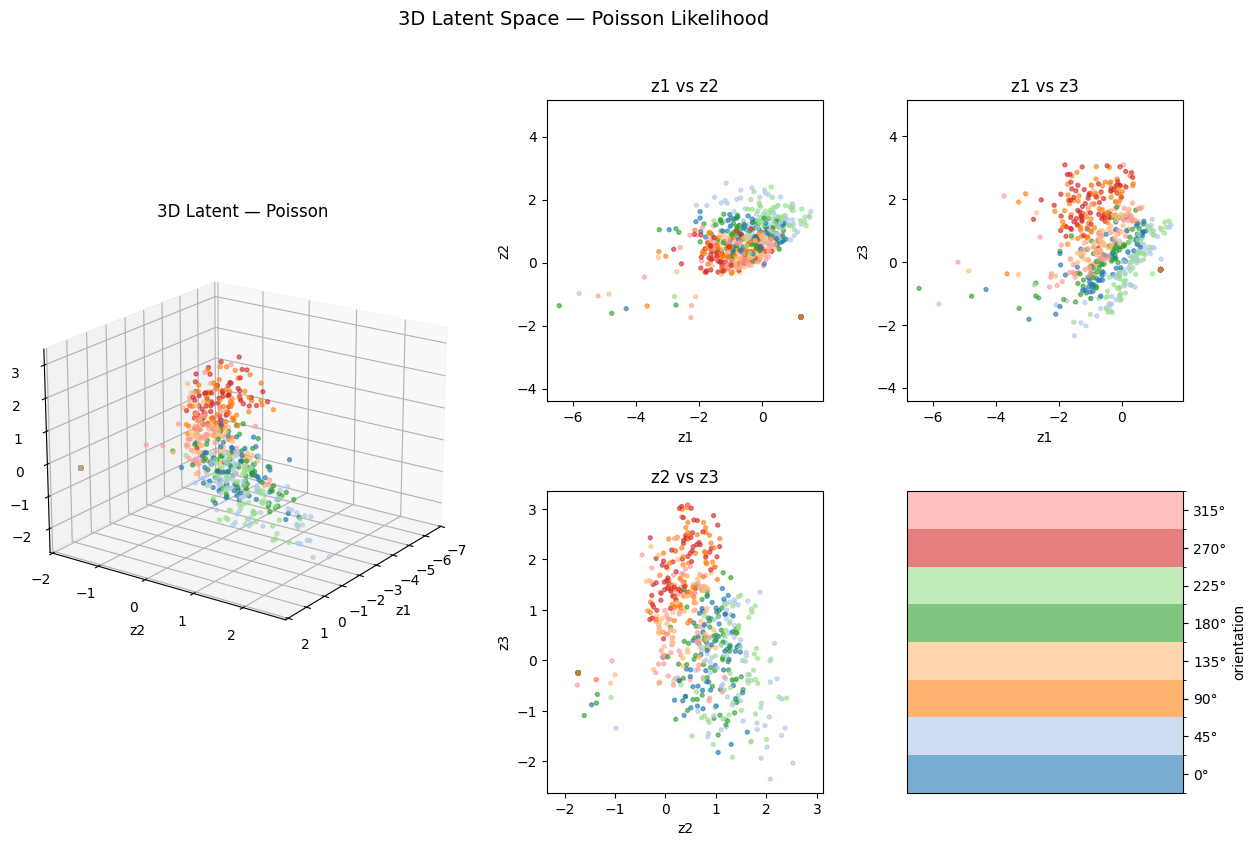

In [10]:
likelihood = "poisson"
vae_3d_model_p = run_VAE(X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=3)

vae_3d_model_p.eval()
with torch.no_grad():
    mu_all, _ = vae_3d_model_p.encoder(X)
    Z = mu_all.cpu().numpy() # (n_trials, 3)

cmap = plt.get_cmap("tab20") # 10 distinct colors, take first 8
colors = [cmap(i) for i in range(8)]
norm = mcolors.BoundaryNorm(boundaries=np.arange(-45 / 2, 360, 45), ncolors=8)

# --- figure layout: 2 rows x 3 cols; 3D spans left column (both rows) ---
fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 3, width_ratios=[1.6, 1, 1], wspace=0.25, hspace=0.3)

# ---- (a) 3D scatter (spans left column) ----
ax3d = fig.add_subplot(gs[:, 0], projection="3d")
sc = ax3d.scatter(Z[:, 0], Z[:, 1], Z[:, 2],
                  c=orientation_labels, cmap=cmap, norm=norm,
                  s=8, alpha=0.6)
ax3d.set_xlabel("z1"); ax3d.set_ylabel("z2"); ax3d.set_zlabel("z3")
ax3d.set_title(f"3D Latent — Poisson")
ax3d.view_init(elev=20, azim=35)

# ---- (b) three pairwise 2D projections ----
pairs = [(0, 1), (0, 2), (1, 2)]
proj_axes = [
    fig.add_subplot(gs[0, 1]),  # z1 vs z2
    fig.add_subplot(gs[0, 2]),  # z1 vs z3
    fig.add_subplot(gs[1, 1]),  # z2 vs z3
]
for ax, (i, j) in zip(proj_axes, pairs):
    ax.scatter(Z[:, i], Z[:, j], c=orientation_labels,
               cmap=cmap, norm=norm, s=8, alpha=0.6)
    ax.set_xlabel(f"z{i+1}"); ax.set_ylabel(f"z{j+1}")
    ax.set_title(f"z{i+1} vs z{j+1}")
    ax.set_aspect("equal", adjustable="datalim")

# ---- (c) shared colorbar in the bottom-right empty cell ----
cax = fig.add_subplot(gs[1, 2])
cbar = fig.colorbar(
    sc,
    cax=cax,
    boundaries=norm.boundaries,   # reuse the SAME edges as the scatter's BoundaryNorm
    ticks=orients,                # labels at bin centers (0, 45, ..., 315)
    spacing="proportional",       # draw swatches between boundaries, not tick marks
)
cbar.ax.set_yticklabels([f"{o}°" for o in orients])
cbar.set_label("orientation")

plt.suptitle(f"3D Latent Space — Poisson Likelihood", fontsize=14)
plt.show()